# What trialists did: how much of the campaign gap is trial-week behavior?

Exploratory work behind the memo `docs/designs/memo-what-trialists-did.md`.

**Question.** The best campaign (2016-06) converts trialists at 8.01% and the worst (2016-10) at 3.25%. Once audience is in the model, how much of that gap is associated with what trialists did in trial days 0-4, and which behaviors carry it?

**Inputs.** The pipeline's cached stages (`python -m src.pipeline all` up to `bootstrap`). The who / what / unexplained split and its intervals come from `src/model.py` and `src/bootstrap.py`. This notebook adds the behavior comparison, the activation curve, the split of the behavior effect into activity / volume / taste, and robustness checks.

In [1]:
import json
import sys
import time
from itertools import combinations
from math import factorial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import definitions as d
from src import model

# src.model selects the non-interactive Agg backend for the pipeline; show plots inline here.
%matplotlib inline

CACHE = ROOT / 'data' / 'cache'
FIG = ROOT / 'docs' / 'designs' / 'figures' / 'what-trialists-did'
FIG.mkdir(parents=True, exist_ok=True)
TOP_VIA = d.MATCH_TOP_REGISTERED_VIA
sig = lambda x: 1 / (1 + np.exp(-x))

## 1. Population and the headline split (from the pipeline)

In [2]:
data, info = model.load_population(CACHE, d.MIN_CAMPAIGN_TRIALS, d.MIN_MIX_LEVEL_TRIALS)
point = json.loads((CACHE / 'model_decomposition.json').read_text())
boot = json.loads((CACHE / 'bootstrap_summary.json').read_text())
BEST, WORST = point['best'], point['worst']
print(f"{info['modeled_trials']:,} trials in {len(info['campaigns_modeled'])} campaigns; best {BEST} "
      f"{point['best_rate']:.2%}, worst {WORST} {point['worst_rate']:.2%}, gap {point['gap'] * 100:.2f} pts")
split = pd.DataFrame({
    'points': [point['phi_who'] * 100, point['phi_what'] * 100, point['unexplained'] * 100],
    'share': [point['share_who'], point['share_what'], point['share_unexplained']],
    'share_lo': [boot['ci95'][q][0] for q in ('share_who', 'share_what', 'share_unexplained')],
    'share_hi': [boot['ci95'][q][1] for q in ('share_who', 'share_what', 'share_unexplained')],
}, index=['who', 'what', 'unexplained'])
split.round(3)

321,506 trials in 7 campaigns; best 2016-06 8.01%, worst 2016-10 3.25%, gap 4.76 pts


,points,share,share_lo,share_hi
who,3.972,0.834,0.739,0.947
what,1.305,0.274,0.230,0.319
unexplained,-0.516,-0.108,-0.259,0.024


## 2. How behavior differs between the best and worst campaign

Share of each campaign's trialists by days with any listening (trial days 0-4). The third column reweights the worst campaign's trialists to the best campaign's audience (matching cell: signup channel x age band): how the worst campaign would behave if it had reached the best campaign's kind of people.

In [3]:
cell, _ = model.matching_keys(data, TOP_VIA)
data = data.assign(cell=cell)
b, w = data[data['campaign'] == BEST], data[data['campaign'] == WORST]


def reweighted(frame, target, col):
    """Distribution of `col` in `frame` after reweighting its cells to `target`'s cell mix."""
    weights = target['cell'].value_counts(normalize=True)
    within = frame.groupby('cell')[col].value_counts(normalize=True).unstack(fill_value=0)
    within = within.reindex(weights.index).fillna(frame[col].value_counts(normalize=True))
    return within.mul(weights, axis=0).sum()


days = pd.DataFrame({
    BEST: b['days_active_band'].value_counts(normalize=True),
    WORST: w['days_active_band'].value_counts(normalize=True),
    f'{WORST} at {BEST} audience': reweighted(w, b, 'days_active_band'),
    'conversion': data.groupby('days_active_band')['converted'].mean(),
}).sort_index() * 100
display(days.round(1))

silent = {k: days.loc['0', k] for k in days.columns[:3]}
closed = (silent[WORST] - silent[f'{WORST} at {BEST} audience']) / (silent[WORST] - silent[BEST])
print(f'Silent share: best {silent[BEST]:.1f}%, worst {silent[WORST]:.1f}%, worst at best audience '
      f'{silent[f"{WORST} at {BEST} audience"]:.1f}% -> audience alone closes {closed:.0%} of the silent-share gap')

listeners = data[data['days_active'] > 0]
intensity = listeners.groupby('campaign')[['listen_minutes', 'daily_unique_songs', 'completion_rate', 'early_skip_share']].median()
intensity.loc[[BEST, WORST]].round(2)

,2016-06,2016-10,2016-10 at 2016-06 audience,conversion
days_active_band,,,,
0,28.5,43.3,40.4,1.0
1,23.7,27.2,23.1,1.4
2,12.7,10.6,11.1,3.7
3,10.1,7.0,8.3,7.2
4,11.2,5.6,7.6,12.3
5,13.8,6.3,9.6,19.2


Silent share: best 28.5%, worst 43.3%, worst at best audience 40.4% -> audience alone closes 20% of the silent-share gap


,listen_minutes,daily_unique_songs,completion_rate,early_skip_share
campaign,,,,
2016-06,106.29,33.0,0.47,0.29
2016-10,52.74,17.0,0.45,0.29


## 3. The activation curve

Raw and audience-adjusted conversion by days active (g-computation from a campaign + audience + days-active model, `src/model.py:activation`).

In [4]:
act = pd.read_parquet(CACHE / 'model_activation.parquet')
act.assign(raw_pct=act['raw_rate'] * 100, adjusted_pct=act['adjusted_rate'] * 100).round(2)

,days_active,n,raw_rate,adjusted_rate,raw_pct,adjusted_pct
0,0,125972,0.01,0.01,1.04,1.16
1,1,86401,0.01,0.02,1.41,1.57
2,2,36689,0.04,0.04,3.74,3.58
3,3,25587,0.07,0.06,7.25,6.35
4,4,22311,0.12,0.10,12.26,9.86
5,5,24546,0.19,0.14,19.18,14.49


## 4. Which behaviors carry the "what" share?

The behavior swap from the decomposition (each worst-campaign trialist keeps their audience and takes the behavior of a best-campaign trialist in the same matching cell), split by Shapley values over three groups:

- **Activity:** days active, first listen day
- **Volume:** listening minutes, unique songs
- **Taste:** completion rate, early-skip share

Individual coefficients aren't interpretable (days active and first listen day are tied together), so only these grouped contributions are reported.

In [5]:
GROUPS = {
    'activity': ('days_active_band', 'first_day_band'),
    'volume': ('minutes_band', 'unique_band'),
    'taste': ('completion_band', 'skip_band'),
}


def what_groups(res, frame, rng, best=BEST, worst=WORST):
    """Behavior swap v(what) and its Shapley split over GROUPS."""
    eta = res.fittedvalues.to_numpy()
    cell, via = model.matching_keys(frame, TOP_VIA)
    camp = frame['campaign'].to_numpy()
    W, B = np.flatnonzero(camp == worst), np.flatnonzero(camp == best)
    donor, _ = model.draw_matched(rng, cell[W], via[W], B, cell[B], via[B])
    parts = {g: model.block_part(res, frame, cols) for g, cols in GROUPS.items()}
    names = list(GROUPS)
    base = sig(eta[W]).mean()
    value = {
        S: sig(eta[W] + sum((parts[g][donor] - parts[g][W] for g in S), np.zeros(len(W)))).mean() - base
        for k in range(len(names) + 1) for S in combinations(names, k)
    }
    n = len(names)
    phi = {
        g: sum(
            factorial(k) * factorial(n - k - 1) / factorial(n)
            * (value[tuple(x for x in names if x in S or x == g)] - value[S])
            for k in range(n) for S in combinations([x for x in names if x != g], k)
        )
        for g in names
    }
    return value[tuple(names)], phi


res = model.fit(data)
v_what, phi_groups = what_groups(res, data, np.random.default_rng(d.DECOMPOSITION_SEED))
assert abs(sum(phi_groups.values()) - v_what) < 1e-12
print(f'Behavior swap: +{v_what * 100:.2f} pts for the worst campaign')
pd.Series({g: f'{p * 100:+.2f} pts ({p / v_what:.0%})' for g, p in phi_groups.items()}, name='split of v(what)')

Behavior swap: +0.80 pts for the worst campaign


activity    +0.32 pts (40%)
volume      +0.37 pts (47%)
taste       +0.10 pts (13%)
Name: split of v(what), dtype: str

## 5. Robustness

In [6]:
rows = []
draws = [model.decompose(res, data, BEST, WORST, np.random.default_rng(s), TOP_VIA) for s in range(20)]
rows.append({'check': 'Random draws repeated 20x (mean)', 'who': np.mean([x['share_who'] for x in draws]),
             'what': np.mean([x['share_what'] for x in draws]),
             'unexplained': np.mean([x['share_unexplained'] for x in draws])})
sd_what = float(np.std([x['share_what'] for x in draws]))

no_profile = [c for c in model.MIX if c not in ('age_band', 'gender')]
f_np = 'converted ~ C(campaign) + ' + ' + '.join(f'C({c})' for c in no_profile + list(model.BEHAVIOR))
r = model.decompose(model.fit(data, f_np), data, BEST, WORST, np.random.default_rng(d.DECOMPOSITION_SEED), TOP_VIA)
rows.append({'check': 'Without age and gender', 'who': r['share_who'], 'what': r['share_what'],
             'unexplained': r['share_unexplained']})

r = model.decompose(model.fit(data, model.ACTIVATION_FORMULA), data, BEST, WORST,
                    np.random.default_rng(d.DECOMPOSITION_SEED), TOP_VIA)
rows.append({'check': 'Days active as the only behavior', 'who': r['share_who'], 'what': r['share_what'],
             'unexplained': r['share_unexplained']})

r = model.decompose(res, data, WORST, BEST, np.random.default_rng(d.DECOMPOSITION_SEED), TOP_VIA)
rows.append({'check': 'Other direction (best campaign given worst)', 'who': r['share_who'],
             'what': r['share_what'], 'unexplained': r['share_unexplained']})
robust = pd.DataFrame(rows).set_index('check')
print(f'sd of the what share over 20 draws: {sd_what:.2%}')
(robust * 100).round(1)

sd of the what share over 20 draws: 0.72%


,who,what,unexplained
check,,,
Random draws repeated 20x (mean),83.6,27.5,-11.1
Without age and gender,82.3,27.6,-9.9
Days active as the only behavior,82.6,26.4,-9.0
Other direction (best campaign given worst),78.9,25.1,-4.1


## 6. Bootstrap for the behavior-group split

The pipeline's bootstrap covers who / what / unexplained. This adds intervals for the activity / volume / taste split: 200 replicates, trialists resampled within campaign, refit each time, best and worst fixed. About 7 s per replicate.

Each replicate's fit holds a ~136 MB design matrix inside reference cycles, which a long-lived kernel frees too late; an earlier run died of it. So the loop keeps only the model's columns, releases each fit and collects garbage every replicate. Replicates are saved to `data/cache/what_groups_bootstrap.csv` as they finish, and a rerun resumes from there.

In [7]:
import gc

KEEP = ['campaign', 'converted', *model.MIX, *model.BEHAVIOR]
slim = data[KEEP]
CHECKPOINT = CACHE / 'what_groups_bootstrap.csv'
done = pd.read_csv(CHECKPOINT) if CHECKPOINT.exists() else pd.DataFrame()
rng = np.random.default_rng(d.BOOTSTRAP_SEED)
groups_idx = [slim.index[slim['campaign'] == c].to_numpy() for c in sorted(slim['campaign'].unique())]
t0 = time.time()
for b in range(d.BOOTSTRAP_REPLICATES):
    # Draw every replicate's resample even when resuming, so the random stream matches a fresh run.
    idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups_idx])
    draw_rng = np.random.default_rng([d.BOOTSTRAP_SEED, b])
    if b < len(done):
        continue
    sample = slim.loc[idx].reset_index(drop=True)
    fit_b = model.fit(sample)
    v, phi = what_groups(fit_b, sample, draw_rng)
    row = pd.DataFrame([{'replicate': b, 'v_what': v, **{g: p / v for g, p in phi.items()}}])
    row.to_csv(CHECKPOINT, mode='a', header=not CHECKPOINT.exists(), index=False)
    del sample, fit_b
    gc.collect()
reps = pd.read_csv(CHECKPOINT)
assert len(reps) == d.BOOTSTRAP_REPLICATES, len(reps)
print(f'{len(reps)} replicates ({(time.time() - t0) / 60:.1f} min this run)')
group_ci = reps.quantile([0.025, 0.975])
group_ci

200 replicates (0.0 min this run)


,replicate,v_what,activity,volume,taste
0.025,4.975,0.007070,0.341943,0.411016,0.087433
0.975,194.025,0.009429,0.458128,0.529210,0.172441


## 7. Figures for the memo

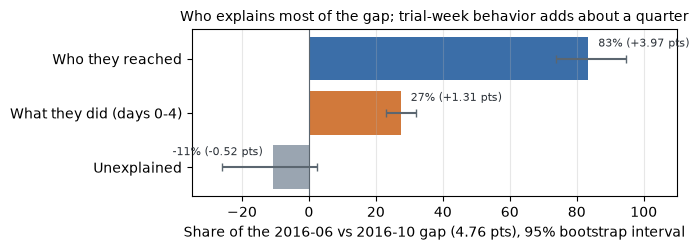

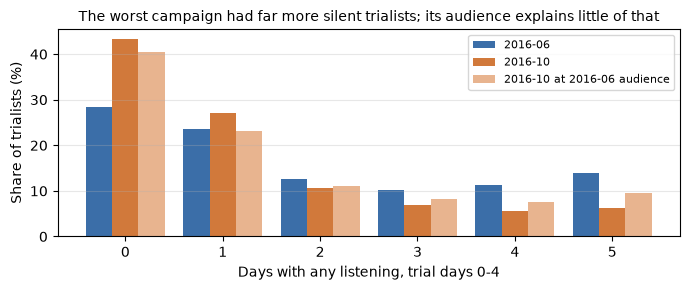

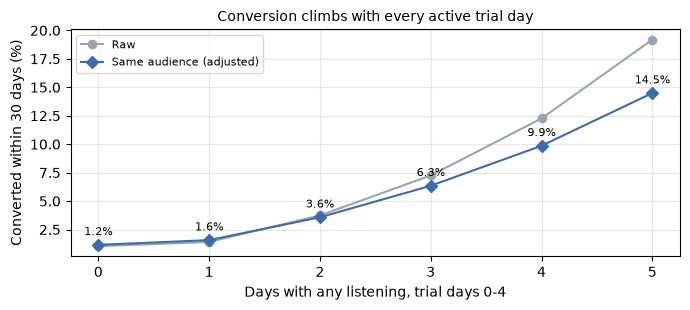

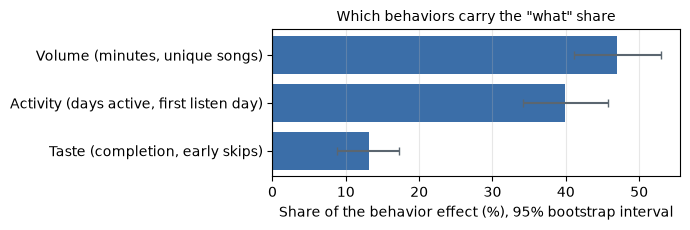

In [8]:
BLUE, GREY, DARK = '#3b6ea8', '#9aa5b1', '#2b3138'

# Chart 1: who / what / unexplained, signed, with 95% intervals.
fig, ax = plt.subplots(figsize=(7, 2.6))
labels = ['Who they reached', 'What they did (days 0-4)', 'Unexplained']
y = np.arange(3)[::-1]
ax.barh(y, split['share'] * 100, color=[BLUE, '#d1793b', GREY],
        xerr=[(split['share'] - split['share_lo']) * 100, (split['share_hi'] - split['share']) * 100],
        ecolor='#5b6670', capsize=3)
for yi, (s, pts) in zip(y, zip(split['share'], split['points'])):
    ax.text(s * 100 + (3 if s >= 0 else -3), yi + 0.28, f'{s:.0%} ({pts:+.2f} pts)',
            ha='left' if s >= 0 else 'right', va='center', fontsize=8, color=DARK)
ax.axvline(0, color='#5b6670', lw=0.8)
ax.set_yticks(y, labels)
ax.set_xlim(-35, 110)
ax.set_xlabel(f'Share of the {BEST} vs {WORST} gap ({point["gap"] * 100:.2f} pts), 95% bootstrap interval')
ax.set_title('Who explains most of the gap; trial-week behavior adds about a quarter', fontsize=10)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / 'chart1_who_what_split.png', dpi=150)
plt.show()

# Chart 2: days active, best vs worst vs worst at best audience.
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(days.index))
for i, (col, color) in enumerate(zip(days.columns[:3], [BLUE, '#d1793b', '#e8b48f'])):
    ax.bar(x + (i - 1) * 0.27, days[col], width=0.27, color=color, label=col)
ax.set_xticks(x, days.index)
ax.set_xlabel('Days with any listening, trial days 0-4')
ax.set_ylabel('Share of trialists (%)')
ax.set_title('The worst campaign had far more silent trialists; its audience explains little of that', fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / 'chart2_days_active.png', dpi=150)
plt.show()

# Chart 3: the activation curve.
fig, ax = plt.subplots(figsize=(7, 3.2))
xa = act['days_active'].astype(int)
ax.plot(xa, act['raw_rate'] * 100, 'o-', color=GREY, label='Raw')
ax.plot(xa, act['adjusted_rate'] * 100, 'D-', color=BLUE, label='Same audience (adjusted)')
for xi, yi in zip(xa, act['adjusted_rate'] * 100):
    ax.annotate(f'{yi:.1f}%', (xi, yi), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax.set_xlabel('Days with any listening, trial days 0-4')
ax.set_ylabel('Converted within 30 days (%)')
ax.set_title('Conversion climbs with every active trial day', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'chart3_activation.png', dpi=150)
plt.show()

# Chart 4: activity / volume / taste split of the behavior effect.
shares = pd.Series({g: p / v_what * 100 for g, p in phi_groups.items()})
lo, hi = group_ci.loc[0.025, shares.index] * 100, group_ci.loc[0.975, shares.index] * 100
names = {'activity': 'Activity (days active, first listen day)', 'volume': 'Volume (minutes, unique songs)',
         'taste': 'Taste (completion, early skips)'}
fig, ax = plt.subplots(figsize=(7, 2.4))
order = shares.sort_values().index
ax.barh([names[g] for g in order], shares[order], color=BLUE,
        xerr=[shares[order] - lo[order], hi[order] - shares[order]], ecolor='#5b6670', capsize=3)
ax.axvline(0, color='#5b6670', lw=0.8)
ax.set_xlabel('Share of the behavior effect (%), 95% bootstrap interval')
ax.set_title('Which behaviors carry the "what" share', fontsize=10)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / 'chart4_behavior_groups.png', dpi=150)
plt.show()

## 8. Summary (numbers quoted in the memo)

In [9]:
summary = {
    'modeled_trials': info['modeled_trials'], 'best': BEST, 'worst': WORST,
    'best_rate': point['best_rate'], 'worst_rate': point['worst_rate'], 'gap': point['gap'],
    'split': split.reset_index().to_dict('records'),
    'days_active_pct': days.round(2).reset_index().to_dict('records'),
    'silent_closed_by_audience': closed,
    'listener_medians': intensity.loc[[BEST, WORST]].reset_index().to_dict('records'),
    'activation': act.to_dict('records'),
    'v_what': v_what, 'behavior_group_share': {g: p / v_what for g, p in phi_groups.items()},
    'behavior_group_ci': {g: [group_ci.loc[0.025, g], group_ci.loc[0.975, g]] for g in GROUPS},
    'robustness': robust.reset_index().to_dict('records'), 'what_share_draw_sd': sd_what,
    'pseudo_r2': point['pseudo_r2'],
}
(ROOT / 'notebooks' / 'what_trialists_did_results.json').write_text(json.dumps(summary, indent=2, default=float))
{k: v for k, v in summary.items() if k in ('silent_closed_by_audience', 'v_what', 'behavior_group_share', 'behavior_group_ci')}

{'silent_closed_by_audience': np.float64(0.19631425909129874),
 'v_what': np.float64(0.007967098584515393),
 'behavior_group_share': {'activity': np.float64(0.3989627163880532),
  'volume': np.float64(0.46941698247537506),
  'taste': np.float64(0.13162030113657172)},
 'behavior_group_ci': {'activity': [np.float64(0.3419425898911568),
   np.float64(0.458128449305563)],
  'volume': [np.float64(0.4110155919161529), np.float64(0.5292095728224769)],
  'taste': [np.float64(0.08743337665515649), np.float64(0.17244144956926882)]}}